In [4]:
# Import relevant Libraries for Credit risk model 

import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, roc_curve

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

# Make a folder filepath where the file is stored from which we do our modeling with auto char saving-

FOLDER = r"C:\Users\gagan\Downloads\Portfolios\credit risk Project\pd.scorecard"   # <-- CHANGE to your project folder
CHARTS = os.path.join(FOLDER, "charts")
os.makedirs(CHARTS, exist_ok=True)

SEED = 42            # fixed seed so the train/validation split is reproducible
IV_MIN = 0.02        # variables below this Information Value are dropped
N_BINS = 10          # starting number of quantile bins for numeric variables

# Score scale: BASE_SCORE points at BASE_ODDS (good:bad), and PDO points to double the odds
BASE_SCORE, BASE_ODDS, PDO = 600, 20, 20
print("Setup done")

Setup done


In [5]:
# upload the data with pandas 

df = pd.read_parquet(os.path.join(FOLDER, "lc_clean_v2.parquet"))
print("full data:", df.shape)

# Split by TIME first: 2013-2014 = development data, 2015 = out-of-time (OOT) test
dev = df[df["issue_year"].isin([2013, 2014])].copy()
oot = df[df["issue_year"] == 2015].copy()

# Then split development data 70/30 into train and validation (random, stratified on the target)
train, val = train_test_split(dev, test_size=0.30, random_state=SEED, stratify=dev["bad"])
train, val = train.copy(), val.copy()

summary = pd.DataFrame({
    "loans": [len(train), len(val), len(oot)],
    "default_rate_%": [train["bad"].mean() * 100, val["bad"].mean() * 100, oot["bad"].mean() * 100],
}, index=["train (2013-14)", "validation (2013-14)", "OOT (2015)"]).round(2)
summary

full data: (546016, 33)


,loans,default_rate_%
train (2013-14),184093,13.19
validation (2013-14),78898,13.19
OOT (2015),283025,14.89


In [6]:
# Candidate model variables. Excluded on purpose: id, loan_status, bad (target), grade, sub_grade,
# int_rate (Lending Club's own risk outputs), fico_range_low/high (duplicates of bureau_score),
# issue_d / issue_year / earliest_cr_line (dates already converted), addr_state (many categories, fairness concerns)
num_vars = ["bureau_score", "obligation_ratio", "income", "loan_amnt", "utilization",
            "credit_history_years", "enquiries_6m", "delinq_count_2y", "open_acc", "total_acc",
            "pub_rec", "pub_rec_bankruptcies", "revol_bal", "mort_acc", "emp_length_yrs",
            "mths_since_last_delinq"]
cat_vars = ["home_ownership", "verification_status", "purpose"]
flag_vars = ["emp_missing_flag", "never_delinq_flag"]
ALL_VARS = num_vars + cat_vars + flag_vars

# Safety checks
forbidden = {"grade", "sub_grade", "int_rate", "bad", "loan_status", "fico_range_low", "fico_range_high", "id"}
assert not (set(ALL_VARS) & forbidden), "A forbidden column is in the variable list!"
assert train[ALL_VARS].isna().sum().sum() == 0, "There are missing values left in candidate variables"
print(len(ALL_VARS), "candidate variables, no forbidden columns, no missing values")

21 candidate variables, no forbidden columns, no missing values


In [7]:
# make edges from the series as per the bin_size consider only unqiue and matched values from series to percetiles-

def make_edges(series, n_bins=N_BINS):
    """Quantile bin edges from a numeric series. Duplicate edges are removed (tied values give fewer bins).
    The first and last edges are +/- infinity so unseen values in validation/OOT always land in a bin."""
    edges = np.unique(np.quantile(series, np.linspace(0, 1, n_bins + 1)))
    edges[0], edges[-1] = -np.inf, np.inf
    return edges

# Make a bin as per the edged data we have from series-

def bin_numeric(series, edges):
    """Return the bin number (0, 1, 2, ...) of each value."""
    return pd.cut(series, bins=edges, labels=False, include_lowest=True)

# Our main engine for the work takes data from series - binned and analyze bad- 
# loans as per bins distribite (good, bad) - bin wise by total good and bad and see the bins wise WOE(weight of evidence) and IV (info- Value) 

def woe_table(binned, y, smooth=0.5):
    """WOE and IV per bin. smooth=0.5 is added to goods and bads so no bin gives log(0)."""
    d = pd.DataFrame({"bin": np.asarray(binned), "bad": np.asarray(y)})
    g = d.groupby("bin", observed=True)["bad"].agg(loans="count", bads="sum")
    g["goods"] = g["loans"] - g["bads"]
    bads, goods = g["bads"] + smooth, g["goods"] + smooth
    g["dist_good"] = goods / goods.sum()
    g["dist_bad"] = bads / bads.sum()
    g["woe"] = np.log(g["dist_good"] / g["dist_bad"])        # positive = safer than average
    g["iv_part"] = (g["dist_good"] - g["dist_bad"]) * g["woe"]
    g["bad_rate_%"] = 100 * g["bads"] / g["loans"]
    return g

# we create a small demo of how our function woe_table work consider good = 800, bad = 200
y_test = np.array([0]*300 + [1]*30 + [0]*300 + [1]*60 + [0]*200 + [1]*110)
b_test = np.array(["A"]*330 + ["B"]*360 + ["C"]*310)
t = woe_table(b_test, y_test, smooth=0)
print(t[["loans", "bads", "woe", "iv_part"]].round(3))
print("Total IV:", round(t["iv_part"].sum(), 3), "  (expected: WOE +0.916, +0.223, -0.788 and IV about 0.46)")

     loans  bads    woe  iv_part
bin                             
A      330    30  0.916    0.206
B      360    60  0.223    0.017
C      310   110 -0.788    0.237
Total IV: 0.459   (expected: WOE +0.916, +0.223, -0.788 and IV about 0.46)


In [18]:
# Make a summarized IV(information value) by each variable(column) and check its effect on default rates by category = weak, strong etc
# And store it in dekstop filr as 'iv_table_csv'--

edges, tables = {}, {}
for c in num_vars : 
     edges[c] = make_edges(train[c])
     tables[c] = woe_table(bin_numeric(train[c], edges[c]), train["bad"])

for c in cat_vars + flag_vars :
    tables[c] = woe_table(train[c], train["bad"])

iv = pd.Series({c : tables[c]["iv_part"].sum() for c in tables }).sort_values(ascending = False)
iv_table = iv.round(4).to_frame("IV")
iv_table["strength"] = pd.cut(iv_table["IV"], [-1, 0.02, 0.1, 0.3, 0.5, 10],
                             labels = ["useless", "weak", "medium", "strong", "suspicious-check_leakage"])
iv_table["decision"] = np.where(iv_table["IV"] >= IV_MIN, "keep", "drop")
iv_table.to_csv(os.path.join(FOLDER, "iv_table.csv"))
iv_table


,IV,strength,decision
bureau_score,0.1342,medium,keep
income,0.0922,weak,keep
obligation_ratio,0.0523,weak,keep
home_ownership,0.0419,weak,keep
mort_acc,0.0417,weak,keep
credit_history_years,0.0236,weak,keep
purpose,0.0212,weak,keep
revol_bal,0.0203,weak,keep
enquiries_6m,0.0197,useless,drop
utilization,0.0185,useless,drop


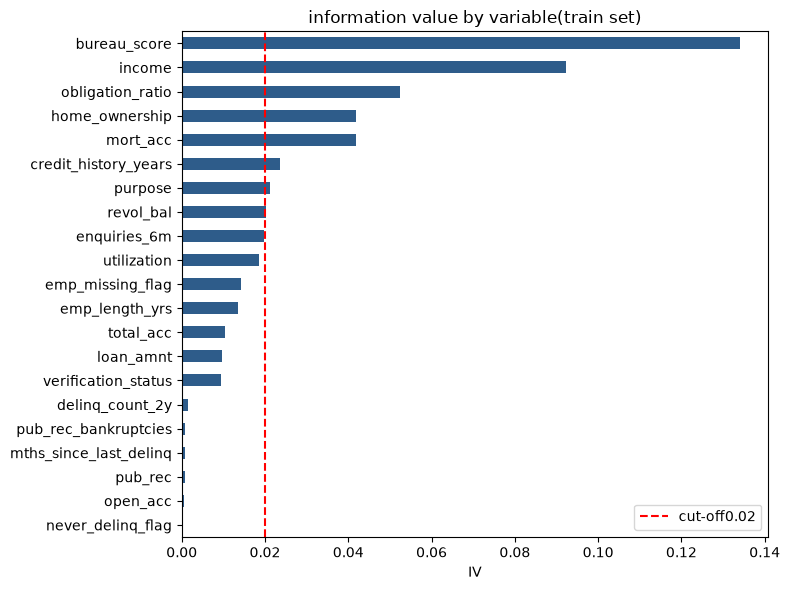

In [24]:
# This IV visual Layout by category is showing you which column vaiable have more predictable power for our model then other 
# for credit risk preictable power - for overall default rate

ax = iv.sort_values().plot(kind = "barh", figsize = (8, 6), color = "#2E5C8A")
ax.axvline(IV_MIN, color = "red", linestyle = '--', label = f"cut-off{IV_MIN}")
ax.set_title("information value by variable(train set)")
ax.set_xlabel("IV")
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(CHARTS, "10_iv.png"), dpi = 120)
plt.show()

8 variables selected: ['bureau_score', 'income', 'obligation_ratio', 'home_ownership', 'mort_acc', 'credit_history_years', 'purpose', 'revol_bal']


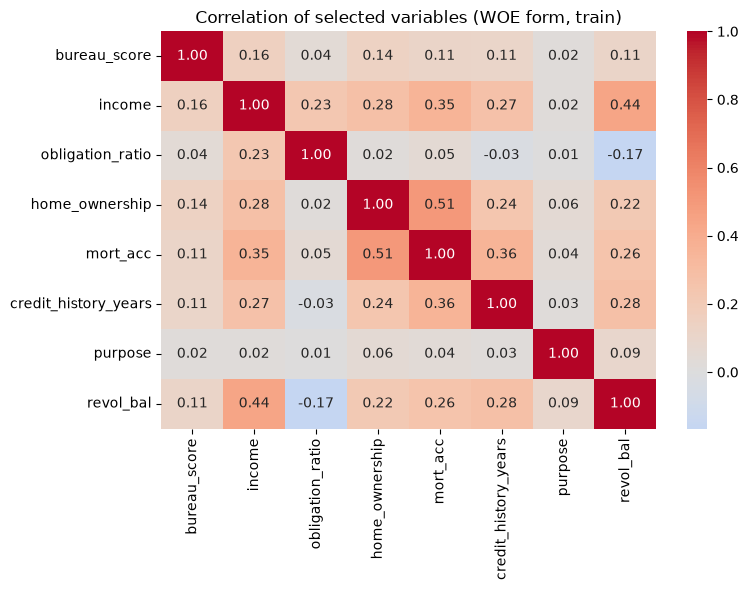

Highest correlated pair: ('home_ownership', 'mort_acc') 0.51 (drop one of a pair if above about 0.7)


In [25]:
# standerdise for regression the value of variables with WOE ( weight of evidence ) for each column variable

def to_woe(d, variables):
    """Replace each variable with its WOE value, using the TRAIN edges and TRAIN WOE only."""
    out = {}
    for c in variables:
        b = bin_numeric(d[c], edges[c]) if c in num_vars else d[c]
        out[c] = b.map(tables[c]["woe"]).fillna(0.0).astype(float).values   # unseen category -> 0 (average)
    return pd.DataFrame(out, index=d.index)

selected = iv[iv >= IV_MIN].index.tolist()
print(len(selected), "variables selected:", selected)

# 1) Correlation between the selected variables (in WOE form)
corr = to_woe(train, selected).corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation of selected variables (WOE form, train)")
plt.tight_layout()
plt.savefig(os.path.join(CHARTS, "11_woe_corr.png"), dpi=120)
plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack().abs().sort_values(ascending=False)
print("Highest correlated pair:", pairs.index[0], round(pairs.iloc[0], 2), "(drop one of a pair if above about 0.7)")

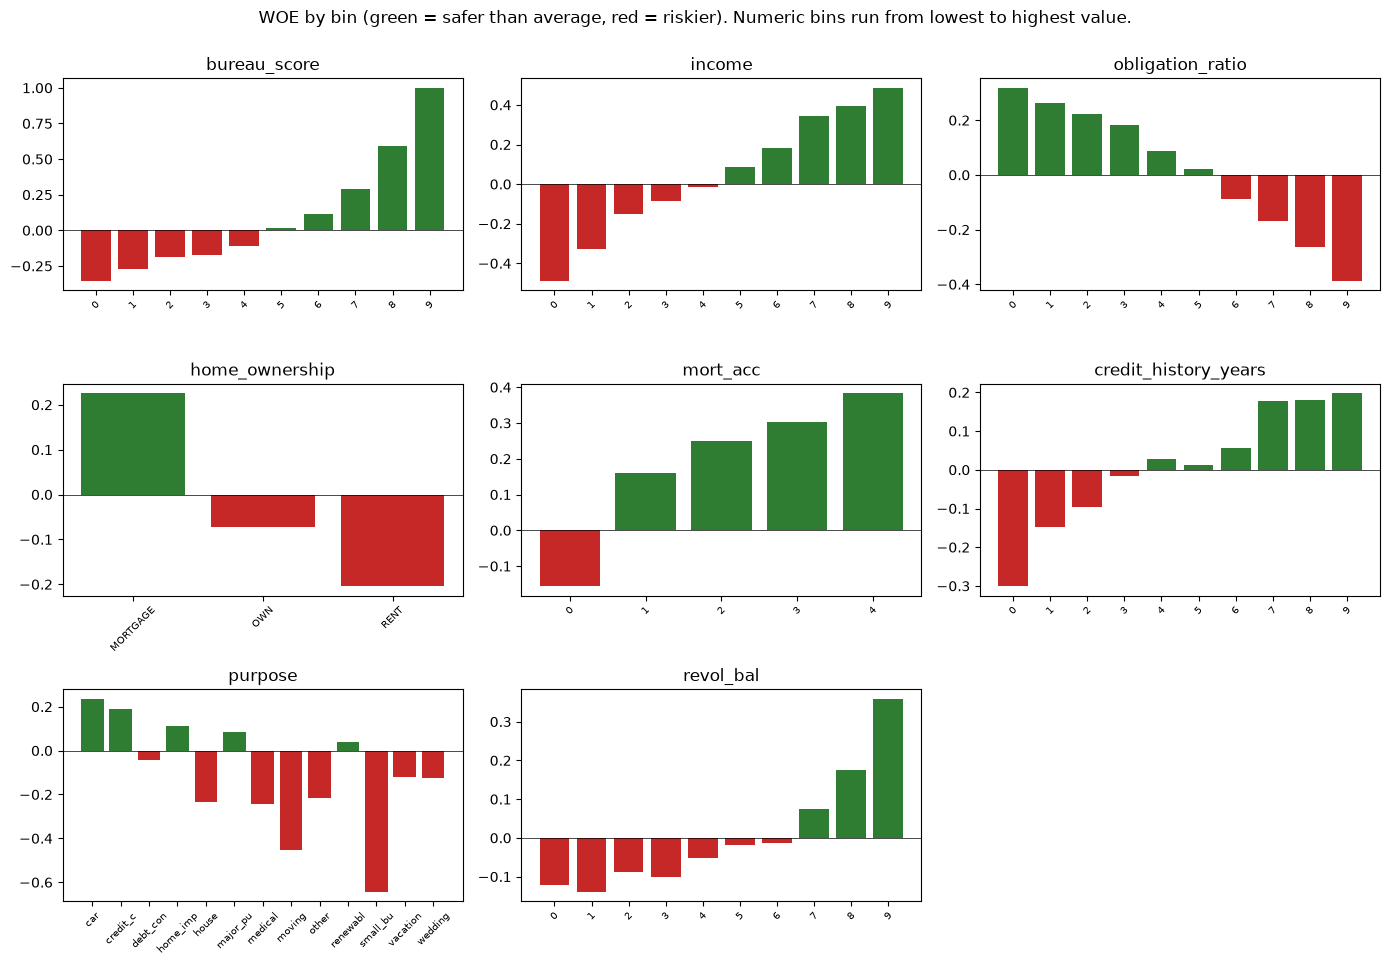

In [26]:
# An Intutive charts showing WOE(Weight of evidence) by Bins for each variables as negative values means riskier shown as red
# and green value shown as positive for woe less riskier and safe compartitively-

n = len(selected)
cols = 3
rows = int(np.ceil(n / cols))
fig, axes = plt.subplots(rows, cols, figsize=(14, 3.2 * rows))
for ax, c in zip(axes.ravel(), selected):
    w = tables[c]["woe"]
    ax.bar(range(len(w)), w.values, color=np.where(w.values >= 0, "#2E7D32", "#C62828"))
    ax.set_title(c)
    ax.set_xticks(range(len(w)))
    ax.set_xticklabels([str(i) if c in num_vars else str(i)[:8] for i in w.index], rotation=45, fontsize=7)
    ax.axhline(0, color="black", linewidth=0.5)
for ax in axes.ravel()[n:]:
    ax.axis("off")
fig.suptitle("WOE by bin (green = safer than average, red = riskier). Numeric bins run from lowest to highest value.", y=1.0)
plt.tight_layout()
plt.savefig(os.path.join(CHARTS, "12_woe_trends.png"), dpi=120)
plt.show()

In [28]:
# See the coffecient relation for each variable to see the relation between them if they are having, 
# any relation shown as postive we remove one of them to make model less noisey as both work the same way

X_train, X_val, X_oot = to_woe(train, selected), to_woe(val, selected), to_woe(oot, selected)

model = LogisticRegression(max_iter=1000)       # default L2 regularisation, fine for WOE inputs
model.fit(X_train, train["bad"])

coef = pd.DataFrame({"variable": selected, "coefficient": model.coef_[0].round(3)}).set_index("variable")
print("Intercept:", round(model.intercept_[0], 3))
print("All coefficients negative?", bool((model.coef_[0] < 0).all()))
coef

Intercept: -1.886
All coefficients negative? True


,coefficient
variable,
bureau_score,-0.865
income,-0.527
obligation_ratio,-0.814
home_ownership,-0.366
mort_acc,-0.247
credit_history_years,-0.285
purpose,-0.905
revol_bal,-0.109


In [29]:
# RUN AUC, GINI for cheacking and ensuring model intution to expected results are storng or not - 
# as gini is just scaled version of AUC both do the same tasks. and KS for finding the diff betweeen change in good and bad-
# Gini ranges from 0 (random) to 1 (perfect), corresponding to AUC from 0.5 to 1.0.
# In consumer credit risk, an AUC around 0.67 (Gini 0.34) shows moderate, usable predictive power,
# while a Gini of ~0.24 (AUC ~0.62) indicates a modest but positive signal (common in OOT validation).is strong sigh there for gini .237 is strong there
def ks_stat(y, p):
    fpr, tpr, _ = roc_curve(y, p)
    return float(np.max(tpr - fpr))

train["pd"] = model.predict_proba(X_train)[:, 1]
val["pd"] = model.predict_proba(X_val)[:, 1]
oot["pd"] = model.predict_proba(X_oot)[:, 1]

rows = []
for name, d in [("Train", train), ("Validation", val), ("OOT 2015", oot)]:
    auc = roc_auc_score(d["bad"], d["pd"])
    rows.append({"set": name, "loans": len(d), "AUC": auc, "Gini": 2 * auc - 1, "KS": ks_stat(d["bad"], d["pd"])})
metrics = pd.DataFrame(rows).set_index("set").round(3)
metrics

,loans,AUC,Gini,KS
set,,,,
Train,184093,0.641,0.282,0.203
Validation,78898,0.637,0.274,0.202
OOT 2015,283025,0.639,0.278,0.201


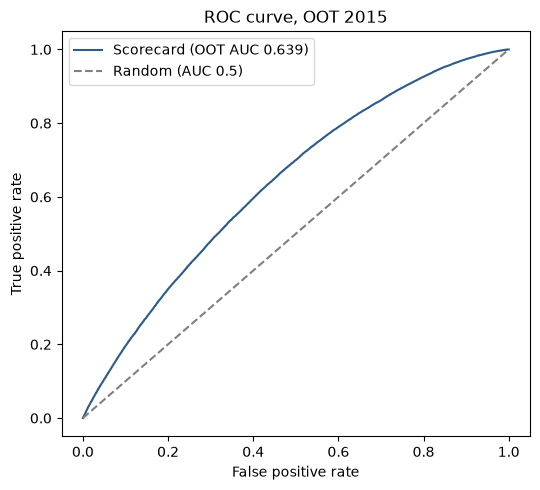

In [30]:
# Visual layout showing AUC at random 0.5 means model giving random response and seeing our 
# model scorecard as 0.639 is showing our model prdeictive power is strong

fpr, tpr, _ = roc_curve(oot["bad"], oot["pd"])
plt.figure(figsize=(5.5, 5))
plt.plot(fpr, tpr, label=f"Scorecard (OOT AUC {roc_auc_score(oot['bad'], oot['pd']):.3f})", color="#2E5C8A")
plt.plot([0, 1], [0, 1], "--", color="grey", label="Random (AUC 0.5)")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("ROC curve, OOT 2015"); plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(CHARTS, "13_roc_oot.png"), dpi=120)
plt.show()

In [31]:
# the scorecard clearly beats the bureau score alone (0.601), so the extra variables add value. 
# It gives up only about 0.024 AUC to gradient boosting, in exchange for full explainability.
# Lending Club's grade and rate do better because they used information not available here (for example, their internal data).

gmap = {g: i for i, g in enumerate("ABCDEFG")}      # A = 0 (safest) ... G = 6 (riskiest)

raw_feats = num_vars + flag_vars
gb = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.1, random_state=SEED)
gb.fit(train[raw_feats], train["bad"])

bench = pd.DataFrame({
    "OOT AUC": {
        "Scorecard (WOE logistic regression)": roc_auc_score(oot["bad"], oot["pd"]),
        "Gradient boosting (raw variables)": roc_auc_score(oot["bad"], gb.predict_proba(oot[raw_feats])[:, 1]),
        "Lending Club grade (A=0 ... G=6)": roc_auc_score(oot["bad"], oot["grade"].map(gmap)),
        "Lending Club int_rate": roc_auc_score(oot["bad"], oot["int_rate"]),
        "Bureau score alone": roc_auc_score(oot["bad"], -oot["bureau_score"]),   # minus: higher score = lower risk
    }
}).round(3)
bench

,OOT AUC
Scorecard (WOE logistic regression),0.639
Gradient boosting (raw variables),0.663
Lending Club grade (A=0 ... G=6),0.668
Lending Club int_rate,0.678
Bureau score alone,0.601


In [32]:
# ensure to check the diff in model prediction and actual number for data stablity and check its stablity by PSI-
# Population stablity index and find out most of the changes is not because of unstable model and acutal number diff it is very
# low real reason is somthing else mix of the default rate is rising as such other factors like macro without and diff in mix of grades

oot["decile"] = pd.qcut(oot["pd"], 10, labels=False, duplicates="drop") + 1     # 1 = lowest predicted risk
calib = oot.groupby("decile").agg(loans=("bad", "size"),
                                  predicted_pd_pct=("pd", lambda s: 100 * s.mean()),
                                  actual_default_pct=("bad", lambda s: 100 * s.mean()))
calib["gap_pts"] = calib["actual_default_pct"] - calib["predicted_pd_pct"]
calib = calib.round(2)

def psi(expected, actual, bins=10):
    """Population Stability Index of predicted PD between two groups of loans (cut points from `expected`)."""
    cuts = np.quantile(expected, np.linspace(0, 1, bins + 1))
    cuts[0], cuts[-1] = 0.0, 1.0
    e = np.histogram(expected, cuts)[0] / len(expected)
    a = np.histogram(actual, cuts)[0] / len(actual)
    e, a = np.clip(e, 1e-6, None), np.clip(a, 1e-6, None)
    return float(np.sum((a - e) * np.log(a / e)))

print("PSI train vs validation:", round(psi(train["pd"], val["pd"]), 4))
print("PSI train vs OOT 2015  :", round(psi(train["pd"], oot["pd"]), 4), "(below 0.1 = stable)")
print("Average predicted PD on OOT: %.2f%%   actual default rate: %.2f%%" % (100 * oot["pd"].mean(), 100 * oot["bad"].mean()))
calib

PSI train vs validation: 0.0002
PSI train vs OOT 2015  : 0.0024 (below 0.1 = stable)
Average predicted PD on OOT: 13.44%   actual default rate: 14.89%


,loans,predicted_pd_pct,actual_default_pct,gap_pts
decile,,,,
1,28305,4.72,4.60,-0.12
2,28300,7.22,8.15,0.93
3,28303,9.07,10.28,1.21
4,28302,10.61,11.84,1.23
5,28303,12.08,14.08,1.99
6,28302,13.59,16.04,2.46
7,28302,15.24,17.42,2.18
8,28303,17.20,18.91,1.71
9,28304,19.79,21.75,1.95


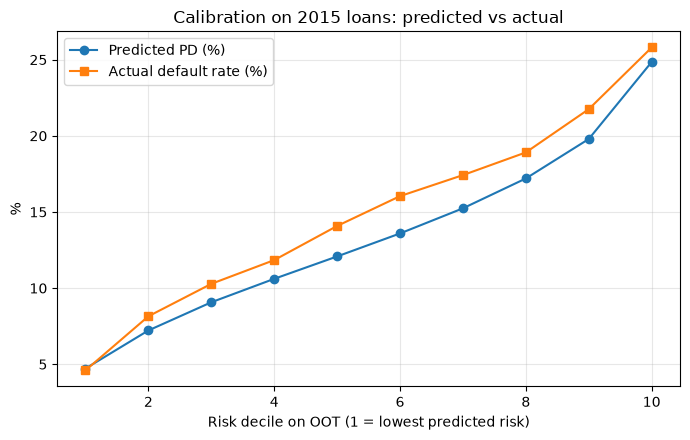

In [33]:
# Our visual layout telling actual risk default is higher then predicted default %

plt.figure(figsize=(7, 4.5))
plt.plot(calib.index, calib["predicted_pd_pct"], marker="o", label="Predicted PD (%)")
plt.plot(calib.index, calib["actual_default_pct"], marker="s", label="Actual default rate (%)")
plt.xlabel("Risk decile on OOT (1 = lowest predicted risk)"); plt.ylabel("%")
plt.title("Calibration on 2015 loans: predicted vs actual"); plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(CHARTS, "14_calibration.png"), dpi=120)
plt.show()

In [34]:
factor = PDO / np.log(2)
offset = BASE_SCORE - factor * np.log(BASE_ODDS)

def pd_to_score(p):
    p = np.clip(np.asarray(p, dtype=float), 1e-6, 1 - 1e-6)
    return offset + factor * np.log((1 - p) / p)       # ln(good odds): higher score = lower risk

# Sanity checks of the formula
print("odds 20:1 (PD = 1/21) ->", round(float(pd_to_score(1/21)), 1), "(expected 600)")
print("odds 40:1 (PD = 1/41) ->", round(float(pd_to_score(1/41)), 1), "(expected 620)")
print("odds 10:1 (PD = 1/11) ->", round(float(pd_to_score(1/11)), 1), "(expected 580)")

for d in (train, val, oot):
    d["score"] = pd_to_score(d["pd"])
print(oot["score"].describe().round(1))

odds 20:1 (PD = 1/21) -> 600.0 (expected 600)
odds 40:1 (PD = 1/41) -> 620.0 (expected 620)
odds 10:1 (PD = 1/11) -> 580.0 (expected 580)
count    283025.0
mean        570.3
std          15.8
min         520.8
25%         559.0
50%         568.9
75%         580.0
max         620.6
Name: score, dtype: float64


In [35]:
# Band edges come from the TRAIN score deciles and are applied to every set (like a real scorecard)
band_edges = np.quantile(train["score"], np.linspace(0, 1, 11))
band_edges[0], band_edges[-1] = -np.inf, np.inf
for d in (train, val, oot):
    d["score_band"] = pd.cut(d["score"], bins=band_edges, labels=False, include_lowest=True) + 1   # 1 = lowest score (riskiest)

def band_range(k):
    lo, hi = band_edges[k - 1], band_edges[k]
    if np.isinf(lo): return f"below {hi:.0f}"
    if np.isinf(hi): return f"{lo:.0f} and above"
    return f"{lo:.0f} to {hi:.0f}"

band_tbl = pd.DataFrame({
    "score_range": [band_range(k) for k in range(1, 11)],
    "train_default_%": (100 * train.groupby("score_band")["bad"].mean()).values,
    "val_default_%": (100 * val.groupby("score_band")["bad"].mean()).values,
    "OOT_default_%": (100 * oot.groupby("score_band")["bad"].mean()).values,
    "OOT_loans": oot.groupby("score_band").size().values,
}, index=range(1, 11)).round(1)
band_tbl.index.name = "band (1 = riskiest)"

print("Default rate falls as the score rises (train)?", bool(band_tbl["train_default_%"].is_monotonic_decreasing))
print("Default rate falls as the score rises (OOT)?  ", bool(band_tbl["OOT_default_%"].is_monotonic_decreasing))
band_tbl

Default rate falls as the score rises (train)? True
Default rate falls as the score rises (OOT)?   True


,score_range,train_default_%,val_default_%,OOT_default_%,OOT_loans
band (1 = riskiest),,,,,
1,below 552,23.8,22.3,25.5,32151
2,552 to 557,19.6,19.7,21.3,29215
3,557 to 562,17.4,17.8,18.7,28531
4,562 to 566,14.7,15.5,17.0,27973
5,566 to 569,13.7,13.5,15.7,28059
6,569 to 573,11.8,12.0,13.9,27158
7,573 to 578,10.8,10.6,11.6,27477
8,578 to 584,8.8,9.1,10.2,27443
9,584 to 593,6.9,6.9,8.0,27393


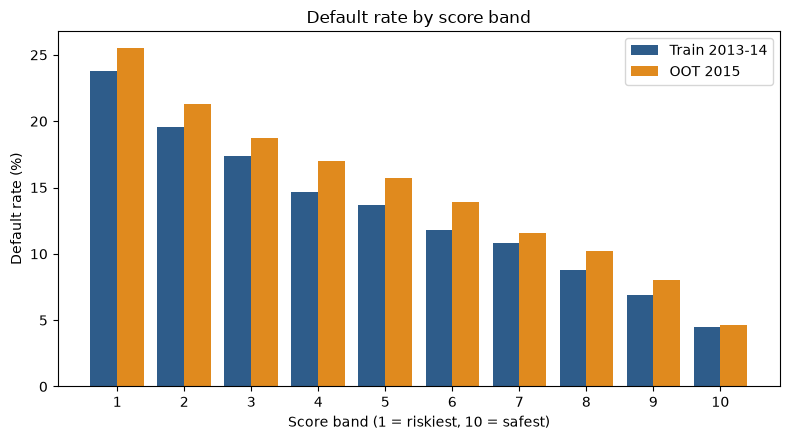

In [36]:
plt.figure(figsize=(8, 4.5))
x = np.arange(1, 11)
plt.bar(x - 0.2, band_tbl["train_default_%"], width=0.4, label="Train 2013-14", color="#2E5C8A")
plt.bar(x + 0.2, band_tbl["OOT_default_%"], width=0.4, label="OOT 2015", color="#E08A1E")
plt.xticks(x); plt.xlabel("Score band (1 = riskiest, 10 = safest)"); plt.ylabel("Default rate (%)")
plt.title("Default rate by score band"); plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(CHARTS, "15_band_default.png"), dpi=120)
plt.show()

In [37]:
# Points per attribute: score = offset + factor * ln(good odds), and ln(good odds) = -(intercept + sum(coef * WOE))
# so each attribute contributes  -factor * coef * WOE  points, and the constant part is shared equally.
b0 = model.intercept_[0]
n_vars = len(selected)
base_points = (offset - factor * b0) / n_vars

def bin_label(c, k):
    if c not in num_vars:
        return str(k)
    lo, hi = edges[c][int(k)], edges[c][int(k) + 1]
    if np.isinf(lo) and np.isinf(hi): return "all values"
    if np.isinf(lo): return f"<= {hi:g}"
    if np.isinf(hi): return f"> {lo:g}"
    return f"({lo:g}, {hi:g}]"

rows = []
for c, b in zip(selected, model.coef_[0]):
    for k, r in tables[c].iterrows():
        rows.append({"variable": c, "bin": bin_label(c, k), "train_loans": int(r["loans"]),
                     "bad_rate_%": round(r["bad_rate_%"], 1), "woe": round(r["woe"], 3),
                     "points": round(base_points - factor * b * r["woe"], 1)})
scorecard = pd.DataFrame(rows)
scorecard.to_csv(os.path.join(FOLDER, "scorecard_points.csv"), index=False)

# Verify: summing the (unrounded) points of each loan's attributes reproduces its score
check = sum(base_points - factor * b * X_oot[c] for c, b in zip(selected, model.coef_[0]))
print("Max difference between summed points and score:", float(np.abs(check - oot["score"]).max()))
scorecard.groupby("variable").head(3)

Max difference between summed points and score: 2.2737367544323206e-13


,variable,bin,train_loans,bad_rate_%,woe,points
0,bureau_score,<= 667,34503,17.8,-0.352,62.2
1,bureau_score,"(667, 672]",17053,16.6,-0.271,64.2
2,bureau_score,"(672, 677]",15006,15.5,-0.189,66.3
10,income,<= 32000,19641,19.8,-0.487,63.6
11,income,"(32000, 40000]",20314,17.4,-0.327,66.0
12,income,"(40000, 47000]",16287,15.0,-0.152,68.7
20,obligation_ratio,<= 7.09,18430,10.0,0.318,78.5
21,obligation_ratio,"(7.09, 10.09]",18397,10.5,0.264,77.2
22,obligation_ratio,"(10.09, 12.46]",18474,10.8,0.222,76.2
30,home_ownership,MORTGAGE,88664,10.8,0.225,73.4


In [38]:
# Save the new filtered clean modified data with our own model derived scores in columns as score and score-band and others save it to our folder

train["split"], val["split"], oot["split"] = "train", "validation", "OOT"
keep = ["id", "split", "issue_year", "grade", "purpose", "home_ownership", "loan_amnt", "int_rate",
        "bad", "pd", "score", "score_band"]
scored = pd.concat([train[keep], val[keep], oot[keep]], ignore_index=True)
scored.to_parquet(os.path.join(FOLDER, "lc_scored.parquet"), index=False)
print("Saved lc_scored.parquet:", scored.shape)

results = {
    "variables_used": len(selected),
    "OOT_AUC": round(metrics.loc["OOT 2015", "AUC"], 3),
    "OOT_Gini": round(metrics.loc["OOT 2015", "Gini"], 3),
    "OOT_KS": round(metrics.loc["OOT 2015", "KS"], 3),
    "PSI_train_vs_OOT": round(psi(train["pd"], oot["pd"]), 4),
    "pred_PD_OOT_%": round(100 * oot["pd"].mean(), 2),
    "actual_default_OOT_%": round(100 * oot["bad"].mean(), 2),
}
results

Saved lc_scored.parquet: (546016, 12)


{'variables_used': 8,
 'OOT_AUC': np.float64(0.639),
 'OOT_Gini': np.float64(0.278),
 'OOT_KS': np.float64(0.201),
 'PSI_train_vs_OOT': 0.0024,
 'pred_PD_OOT_%': np.float64(13.44),
 'actual_default_OOT_%': np.float64(14.89)}